In [ ]:
!git clone https://github.com/qishenzhou/MMTD.git

In [ ]:
%cd MMTD

In [ ]:
pwd

In [ ]:
# MOVE FILES INTO data/mmtd
# mv "/mnt/d/C Drive Data/Downloads/distance_matrix.h5" ~/MMTD/data/mmtd/distance_matrix.h5


In [ ]:
!python -m pip install -r requirements.txt

In [ ]:
%cd ..

In [ ]:
!python -m examples.load_fixed_sensor --data-root ./data

In [ ]:
!git clone https://github.com/nnzhan/Graph-WaveNet.git

In [ ]:
%cd Graph-WaveNet

In [24]:
pwd

'/home/aadiuntu'

In [ ]:
!pip install torch numpy pandas h5py scipy scikit-learn

### Prepare MMTD data

In [2]:

import os
import h5py
import numpy as np
from pathlib import Path

# Locate the MMTD folder
MMTD_ROOT = None

for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "MMTD" / "data").is_dir():
        MMTD_ROOT = base / "MMTD"
        break
    if base.name == "MMTD" and (base / "data").is_dir():
        MMTD_ROOT = base
        break

if MMTD_ROOT is None:
    raise FileNotFoundError("Could not find MMTD/data")

DATA_DIR = MMTD_ROOT / "data"
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Fixed dataset dimensions
TIMESTAMPS = 2976
MAX_NODES = 2078
SEQ_LEN = 12
TARGET_FEATURE = 2

RAW_PATH = DATA_DIR / "fixed_sensor_data.h5"
WEATHER_PATH = DATA_DIR / "fixed_sensor_weather.h5"
WEATHER_256_PATH = DATA_DIR / "fixed_sensor_weather_256.h5"
ROAD_PATH = DATA_DIR / "road_info.h5"
FINAL_PATH = DATA_DIR / "fixed_sensor_weather_road_256.h5"

print("MMTD root:", MMTD_ROOT)
print("Data directory:", DATA_DIR)
print("Timestamps:", TIMESTAMPS)
print("Nodes:", MAX_NODES)
print("Sequence length:", SEQ_LEN)


MMTD root: /home/aadiuntu/MMTD
Data directory: /home/aadiuntu/MMTD/data
Timestamps: 2976
Nodes: 2078
Sequence length: 12


In [3]:

import shutil
import h5py
import numpy as np
import requests

# Reuse an existing weather-enriched file if available
use_existing_weather = False

if WEATHER_PATH.exists():
    with h5py.File(WEATHER_PATH, "r") as f:
        existing_shape = f["data/values"].shape
        existing_features = len(f["metadata/features"])

        if (
            existing_shape[0] >= TIMESTAMPS
            and existing_shape[1] >= MAX_NODES
            and existing_features == 6
        ):
            use_existing_weather = True

if use_existing_weather:
    print("Reusing existing weather-enriched data. No API request.")

    with h5py.File(WEATHER_PATH, "r") as f:
        combined = f["data/values"][
            :TIMESTAMPS, :MAX_NODES, :
        ].astype(np.float32)

        features = [
            x.decode() if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]

        node_ids = f["metadata/nodes"][:MAX_NODES]

    base_path = WEATHER_PATH

else:
    print("No reusable weather file found. Downloading weather.")

    with h5py.File(RAW_PATH, "r") as f:
        traffic = f["data/values"][
            :TIMESTAMPS, :MAX_NODES, :
        ].astype(np.float32)

        old_features = [
            x.decode() if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]

        node_ids = f["metadata/nodes"][:MAX_NODES]

    # Fetch enough historical weather for the first 256 traffic timestamps
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 40.4168,
            "longitude": -3.7038,
            "start_date": "2024-08-01",
            "end_date": "2024-08-03",
            "hourly": "temperature_2m,relative_humidity_2m,precipitation",
            "timezone": "Europe/Madrid",
        },
        timeout=60,
    )
    response.raise_for_status()

    hourly = response.json()["hourly"]

    weather_hourly = np.column_stack([
        hourly["temperature_2m"],
        hourly["relative_humidity_2m"],
        hourly["precipitation"],
    ]).astype(np.float32)

    # Convert hourly weather into 15-minute intervals
    weather_15min = np.repeat(weather_hourly, 4, axis=0)

    weather_15min = weather_15min[:TIMESTAMPS]

    assert len(weather_15min) == TIMESTAMPS

    # Repeat weather across the 256 sensors
    weather_all_sensors = np.broadcast_to(
        weather_15min[:, None, :],
        (TIMESTAMPS, MAX_NODES, 3)
    ).copy()

    combined = np.concatenate(
        [traffic, weather_all_sensors],
        axis=2
    )

    features = old_features + [
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
    ]

    base_path = RAW_PATH


# Save a physically cropped HDF5 file
shutil.copy2(base_path, WEATHER_256_PATH)

with h5py.File(WEATHER_256_PATH, "r+") as f:

    attrs = {}

    if "data/values" in f:
        attrs = dict(f["data/values"].attrs)
        del f["data/values"]

    new_values = f["data"].create_dataset(
        "values",
        data=combined,
        compression="gzip",
        compression_opts=4
    )

    for key, value in attrs.items():
        new_values.attrs[key] = value

    # Ensure metadata contains only the selected nodes
    if "metadata/nodes" in f:
        del f["metadata/nodes"]

    f["metadata"].create_dataset(
        "nodes",
        data=node_ids
    )

    if "metadata/features" in f:
        del f["metadata/features"]

    f["metadata"].create_dataset(
        "features",
        data=np.asarray(
            features,
            dtype=h5py.string_dtype("utf-8")
        )
    )

print("Weather dataset saved:", WEATHER_256_PATH)
print("Shape:", combined.shape)
print("Features:", len(features))



Reusing existing weather-enriched data. No API request.
Weather dataset saved: /home/aadiuntu/MMTD/data/fixed_sensor_weather_256.h5
Shape: (2976, 2078, 6)
Features: 6


In [4]:

import shutil
import h5py
import numpy as np

def node_key(value):
    if isinstance(value, np.generic):
        value = value.item()

    if isinstance(value, bytes):
        value = value.decode("utf-8")

    return str(value).strip()


# Read the cropped weather dataset
with h5py.File(WEATHER_256_PATH, "r") as f:
    traffic_weather = f["data/values"][:].astype(np.float32)
    traffic_nodes = f["metadata/nodes"][:]

    traffic_features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]


# Read road information
with h5py.File(ROAD_PATH, "r") as f:
    road_values = f["data/values"][:].astype(np.float32)
    road_nodes = f["metadata/nodes"][:]

    road_features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]


# Match the selected 256 traffic sensors to road rows
road_row_by_id = {
    node_key(node): i
    for i, node in enumerate(road_nodes)
}

missing = [
    node for node in traffic_nodes
    if node_key(node) not in road_row_by_id
]

print("Selected traffic nodes:", len(traffic_nodes))
print("Unmatched nodes:", len(missing))

if missing:
    raise ValueError(
        f"Some selected sensors have no road match: {missing[:5]}"
    )

row_indices = [
    road_row_by_id[node_key(node)]
    for node in traffic_nodes
]

road_aligned = road_values[row_indices]

# Repeat static road features across 256 timestamps
road_over_time = np.broadcast_to(
    road_aligned[None, :, :],
    (
        TIMESTAMPS,
        MAX_NODES,
        road_aligned.shape[1]
    )
).copy()

# Combine weather, traffic, and road features
combined = np.concatenate(
    [traffic_weather, road_over_time],
    axis=2
)

features = traffic_features + [
    f"road_{name}" for name in road_features
]

print("Final feature count:", len(features))

assert combined.shape[2] == 49, (
    f"Expected 49 features, got {combined.shape[2]}"
)

# Save final dataset
shutil.copy2(WEATHER_256_PATH, FINAL_PATH)

with h5py.File(FINAL_PATH, "r+") as f:

    attrs = dict(f["data/values"].attrs)
    del f["data/values"]

    new_values = f["data"].create_dataset(
        "values",
        data=combined,
        compression="gzip",
        compression_opts=4
    )

    for key, value in attrs.items():
        new_values.attrs[key] = value

    del f["metadata/features"]

    f["metadata"].create_dataset(
        "features",
        data=np.asarray(
            features,
            dtype=h5py.string_dtype("utf-8")
        )
    )

print("Final dataset saved:", FINAL_PATH)
print("Final shape:", combined.shape)


Selected traffic nodes: 2078
Unmatched nodes: 0
Final feature count: 49
Final dataset saved: /home/aadiuntu/MMTD/data/fixed_sensor_weather_road_256.h5
Final shape: (2976, 2078, 49)


### Preprocessing

In [5]:

import shutil
import h5py
import numpy as np
import requests

source_path = DATA_DIR / "fixed_sensor_data.h5"
weather_path = DATA_DIR / "fixed_sensor_weather.h5"

if weather_path.exists():
    print("Weather-enriched file already exists. Skipping API request.")

else:
    print("Downloading historical weather data...")

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 40.4168,
            "longitude": -3.7038,
            "start_date": "2024-08-01",
            "end_date": "2024-08-31",
            "hourly": "temperature_2m,relative_humidity_2m,precipitation",
            "timezone": "Europe/Madrid",
        },
        timeout=60,
    )
    response.raise_for_status()

    hourly = response.json()["hourly"]

    weather_hourly = np.column_stack([
        hourly["temperature_2m"],
        hourly["relative_humidity_2m"],
        hourly["precipitation"],
    ]).astype(np.float32)

    # One hourly weather reading is repeated for four 15-minute intervals
    weather_15min = np.repeat(weather_hourly, 4, axis=0)

    with h5py.File(source_path, "r") as f:
        traffic = f["data/values"][:].astype(np.float32)

        old_features = [
            x.decode() if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]

    T_weather, N_weather, _ = traffic.shape

    assert T_weather == len(weather_15min), (
        f"Traffic timestamps: {T_weather}; "
        f"weather timestamps: {len(weather_15min)}"
    )

    weather_all_sensors = np.broadcast_to(
        weather_15min[:, None, :],
        (T_weather, N_weather, 3)
    ).copy()

    combined = np.concatenate(
        [traffic, weather_all_sensors],
        axis=2
    )

    new_features = old_features + [
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
    ]

    shutil.copy2(source_path, weather_path)

    with h5py.File(weather_path, "r+") as f:
        attrs = dict(f["data/values"].attrs)
        del f["data/values"]

        new_values = f["data"].create_dataset(
            "values",
            data=combined,
            compression="gzip",
            compression_opts=4
        )

        for key, value in attrs.items():
            new_values.attrs[key] = value

        del f["metadata/features"]
        f["metadata"].create_dataset(
            "features",
            data=np.asarray(
                new_features,
                dtype=h5py.string_dtype("utf-8")
            )
        )

    print("Saved:", weather_path)

print("Weather preprocessing complete.")


Weather-enriched file already exists. Skipping API request.
Weather preprocessing complete.


In [ ]:
# mean = values[:train_end].mean(axis=0)
# std = values[:train_end].std(axis=0)
# std[std < 1e-6] = 1.0

# normalized = (values - mean[None, :, :]) / std[None, :, :]

# # Create sliding windows
# # # X: (samples, time, nodes, features)
# # # (T = 2976-12, 12, 256, 3)
# # X = np.stack([
# #     normalized[i:i + SEQ_LEN]
# #     for i in range(T - SEQ_LEN)
# # ])

# # # y: congestion, shape (samples, 1, nodes)
# # # because 1 output feature - (2976-12, 1, 256)
# # y = normalized[SEQ_LEN:, :, TARGET_FEATURE][:, None, :]

# # # Split according to target timestamps
# # train_count = train_end - SEQ_LEN
# # val_count = val_end - train_end

# # splits = {
# #     "train": (X[:train_count], y[:train_count]),
# #     "valid": (
# #         X[train_count:train_count + val_count],
# #         y[train_count:train_count + val_count]
# #     ),
# #     "test": (
# #         X[train_count + val_count:],
# #         y[train_count + val_count:]
# #     )
# # }

# # for name, (x, target) in splits.items():
# #     path = os.path.join(OUTPUT_DIR, f"{name}.npz")
# #     np.savez_compressed(path, x=x, y=target)
# #     print(name, x.shape, target.shape, "->", path)

# # Create memory-mapped sliding windows on D:


# # save preprocessed data
# np.savez(
#     os.path.join(OUTPUT_DIR, "scaler.npz"),
#     mean=mean,
#     std=std,
#     node_ids=node_ids
# )

In [6]:

import h5py
import numpy as np

with h5py.File(FINAL_PATH, "r") as f:
    values = f["data/values"][:].astype(np.float32)
    node_ids = f["metadata/nodes"][:]

    features = [
        x.decode() if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]

T, N, F = values.shape

print("Final dataset shape:", values.shape)
print("Timestamps:", T)
print("Nodes:", N)
print("Features:", F)

assert SEQ_LEN == 12
assert features[TARGET_FEATURE] == "conges_levl"

print("All dimensions correct!")


Final dataset shape: (2976, 2078, 49)
Timestamps: 2976
Nodes: 2078
Features: 49
All dimensions correct!


In [11]:

import gc

# Chronological split
train_end = int(T * 0.70)
val_end = int(T * 0.80)

CHUNK_SIZE = 64

# Convert to float32 if necessary
if values.dtype != np.float32:
    values = values.astype(np.float32)

# --------------------------------------------------
# Calculate per-node, per-feature means
# --------------------------------------------------

sums = np.zeros((N, F), dtype=np.float64)
counts = np.zeros((N, F), dtype=np.int64)

global_sums = np.zeros(F, dtype=np.float64)
global_counts = np.zeros(F, dtype=np.int64)

# Process training data in chunks
for start in range(0, train_end, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, train_end)

    train_values = values[start:end]
    finite_mask = np.isfinite(train_values)

    sums += np.sum(
        train_values,
        axis=0,
        where=finite_mask,
        dtype=np.float64
    )

    counts += finite_mask.sum(axis=0)

    global_sums += np.sum(
        train_values,
        axis=(0, 1),
        where=finite_mask,
        dtype=np.float64
    )

    global_counts += finite_mask.sum(axis=(0, 1))

# Calculate global feature means
global_means = np.divide(
    global_sums,
    global_counts,
    out=np.zeros(F, dtype=np.float64),
    where=global_counts > 0
)

# Calculate node-specific means
node_means = np.divide(
    sums,
    counts,
    out=np.broadcast_to(
        global_means[None, :], (N, F)
    ).copy(),
    where=counts > 0
).astype(np.float32)

del train_values, finite_mask
del sums, counts, global_sums, global_counts
gc.collect()

# --------------------------------------------------
# Replace all NaN and infinite values IN-PLACE
# --------------------------------------------------

for start in range(0, T, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, T)

    train_values = values[start:end]
    bad_mask = ~np.isfinite(train_values)

    np.copyto(
        train_values,
        node_means[None, :, :],
        where=bad_mask
    )

    del bad_mask

del train_values
gc.collect()

# Verify invalid values
invalid_count = 0

for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    invalid_count += (~np.isfinite(values[start:end])).sum()

print("Remaining invalid values:", invalid_count)

assert invalid_count == 0, "Invalid values still exist!"

# --------------------------------------------------
# Normalize using training data only
# --------------------------------------------------

# Calculate mean and standard deviation in chunks
sums = np.zeros((N, F), dtype=np.float64)
squared_sums = np.zeros((N, F), dtype=np.float64)

for start in range(0, train_end, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, train_end)

    train_values = values[start:end]

    sums += train_values.sum(axis=0, dtype=np.float64)

    squared_sums += np.square(
        train_values, dtype=np.float64
    ).sum(axis=0)

mean = (sums / train_end).astype(np.float32)

variance = (
    squared_sums / train_end
) - np.square(sums / train_end)

std = np.sqrt(np.maximum(variance, 0.0)).astype(np.float32)

std[std < 1e-6] = 1.0

del sums, squared_sums, variance
del train_values
gc.collect()

# Save scaler
np.savez(
    OUTPUT_DIR / "scaler_v2.npz",
    mean=mean,
    std=std,
    node_ids=node_ids
)

# Normalize IN-PLACE to avoid creating another full matrix
for start in range(0, T, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, T)

    normalized = values[start:end]

    normalized -= mean[None, :, :]
    normalized /= std[None, :, :]

# Preserve the original variable name
normalized = values

# Verify normalization
assert np.isfinite(normalized).all(), \
    "Normalization produced invalid values!"

# --------------------------------------------------
# Split sample indices
# --------------------------------------------------

train_start = 0
train_stop = train_end - SEQ_LEN

val_start = train_end - SEQ_LEN
val_stop = val_end - SEQ_LEN

test_start = val_end - SEQ_LEN
test_stop = T - SEQ_LEN

print("Normalization complete!")
print("Normalized shape:", normalized.shape)
print("Training samples:", train_stop - train_start)
print("Validation samples:", val_stop - val_start)
print("Testing samples:", test_stop - test_start)


Remaining invalid values: 0
Normalization complete!
Normalized shape: (2976, 2078, 49)
Training samples: 2071
Validation samples: 297
Testing samples: 596


### Load processed datasets

In [12]:

import torch
from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


class TrafficDataset(Dataset):

    def __init__(self, data, start, end):
        self.data = data
        self.start = start
        self.end = end

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, index):

        i = self.start + index

        # Previous 12 timestamps, 256 nodes, 49 features
        x = self.data[i:i + SEQ_LEN]

        # Next timestep's congestion for all 256 nodes
        y = self.data[
            i + SEQ_LEN, :, TARGET_FEATURE
        ][None, :]

        return (
            torch.from_numpy(x.copy()).float(),
            torch.from_numpy(y.copy()).float()
        )


train_dataset = TrafficDataset(
    normalized, train_start, train_stop
)

val_dataset = TrafficDataset(
    normalized, val_start, val_stop
)

test_dataset = TrafficDataset(
    normalized, test_start, test_stop
)

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 2071
Validation samples: 297
Testing samples: 596


### Create NN


In [13]:

import sys
from pathlib import Path

# Locate Graph-WaveNet's model.py
candidates = [
    Path.cwd(),
    Path.cwd() / "Graph-WaveNet",
    MMTD_ROOT.parent / "Graph-WaveNet",
    MMTD_ROOT / "Graph-WaveNet"
]

GW_ROOT = next(
    (p for p in candidates if (p / "model.py").exists()),
    None
)

if GW_ROOT is None:
    raise FileNotFoundError("Could not find Graph-WaveNet/model.py")

sys.path.insert(0, str(GW_ROOT))

from model import gwnet

model = gwnet(
    device=device,
    num_nodes=MAX_NODES,
    dropout=0.1,
    supports=None,
    gcn_bool=True,
    addaptadj=True,
    aptinit=None,
    in_dim=F,              # 49 features
    out_dim=1,
    residual_channels=8,
    dilation_channels=8,
    skip_channels=32,
    end_channels=64,
    kernel_size=2,
    blocks=2,
    layers=2
).to(device)

print("Model initialized!")
print("Input features:", F)
print("Nodes:", MAX_NODES)
print("Sequence length:", SEQ_LEN)
print("Parameters:", sum(p.numel() for p in model.parameters()))


Model initialized!
Input features: 49
Nodes: 2078
Sequence length: 12
Parameters: 47529


### Run input on Model

In [14]:

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# (B, T, N, F) -> (B, F, N, T)
X_batch = X_batch.permute(0, 3, 2, 1).contiguous()

with torch.no_grad():
    output = model(X_batch)

print("Model input:", X_batch.shape)
print("Target:", y_batch.shape)
print("Model output:", output.shape)


Model input: torch.Size([4, 49, 2078, 12])
Target: torch.Size([4, 1, 2078])
Model output: torch.Size([4, 1, 2078, 6])


In [15]:
##sanity check
import numpy as np
import torch

print("RAW DATA")
print("Shape:", values.shape)
print("NaN:", np.isnan(values).sum())
print("Inf:", np.isinf(values).sum())

print("\nTARGET FEATURE")
print("Target index:", TARGET_FEATURE)
print("Target name:", features[TARGET_FEATURE])
print("Target NaNs:", np.isnan(values[:, :, TARGET_FEATURE]).sum())

print("\nNORMALIZED DATA")
print("NaN:", np.isnan(normalized).sum())
print("Inf:", np.isinf(normalized).sum())

# Inspect one batch
x, y = next(iter(train_loader))

print("\nBATCH")
print("X shape:", x.shape)
print("Y shape:", y.shape)
print("X NaNs:", torch.isnan(x).sum().item())
print("Y NaNs:", torch.isnan(y).sum().item())
print("X Infs:", torch.isinf(x).sum().item())
print("Y Infs:", torch.isinf(y).sum().item())


RAW DATA
Shape: (2976, 2078, 49)
NaN: 0
Inf: 0

TARGET FEATURE
Target index: 2
Target name: conges_levl
Target NaNs: 0

NORMALIZED DATA
NaN: 0
Inf: 0

BATCH
X shape: torch.Size([4, 12, 2078, 49])
Y shape: torch.Size([4, 1, 2078])
X NaNs: 0
Y NaNs: 0
X Infs: 0
Y Infs: 0


### Train Model

In [16]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from pathlib import Path

# Set up optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Set up checkpoint in a pytorch model file
checkpoint_path = Path("checkpoints/gwnet_mmtd_best.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")

# Train the model
EPOCHS = 10

history = {"train": [], "validation": []}

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        # Rearrange input for Graph WaveNet
        x = x.permute(0, 3, 2, 1).contiguous()

        # Predict
        optimizer.zero_grad()
        prediction = model(x)
        prediction = prediction[:, :, :, -1]

        # Calculate error - MAE
        loss = F.l1_loss(prediction, y)

        # Learn from the error - backpropagation
        loss.backward()
        optimizer.step()

        # total batch loss
        train_loss += loss.item() * x.size(0)

    # average loss
    train_loss /= len(train_loader.dataset)
    history["train"].append(train_loss)

    # validation
    model.eval()
    val_loss = 0

   # dont compute gradients and dont update weights since its val
    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            x = x.permute(0, 3, 2, 1).contiguous()

            prediction = model(x)
            prediction = prediction[:, :, :, -1]

            loss = F.l1_loss(prediction, y)
            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)

    history["validation"].append(val_loss)

    # results
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train MAE: {train_loss:.4f} | "
        f"Val MAE: {val_loss:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)

print("\nTraining complete!")
print("Best validation MAE:", best_val_loss)
print("Saved model:", checkpoint_path)


Epoch 1/10 | Train MAE: 0.4028 | Val MAE: 0.3196
Epoch 2/10 | Train MAE: 0.3366 | Val MAE: 0.3129
Epoch 3/10 | Train MAE: 0.3287 | Val MAE: 0.3063
Epoch 4/10 | Train MAE: 0.3238 | Val MAE: 0.3062
Epoch 5/10 | Train MAE: 0.3206 | Val MAE: 0.3013
Epoch 6/10 | Train MAE: 0.3185 | Val MAE: 0.3032
Epoch 7/10 | Train MAE: 0.3165 | Val MAE: 0.3002
Epoch 8/10 | Train MAE: 0.3155 | Val MAE: 0.2981
Epoch 9/10 | Train MAE: 0.3144 | Val MAE: 0.2969
Epoch 10/10 | Train MAE: 0.3123 | Val MAE: 0.2960

Training complete!
Best validation MAE: 0.29596295230316394
Saved model: checkpoints/gwnet_mmtd_best.pth


### Plot training and validation error

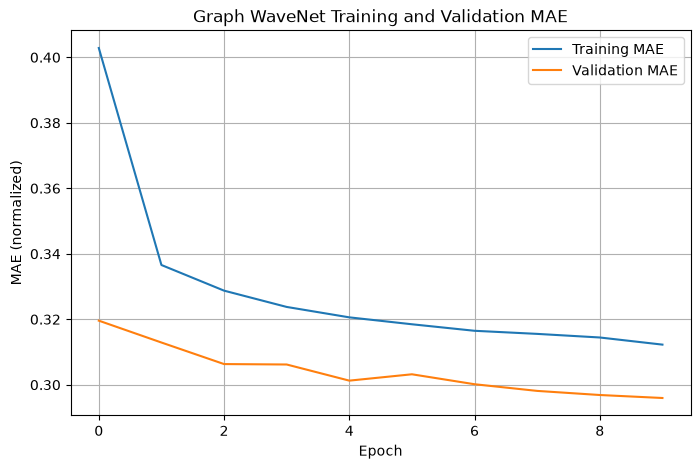

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["train"], label="Training MAE")
plt.plot(history["validation"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Graph WaveNet Training and Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
# Load trained model
model.load_state_dict(
    torch.load("checkpoints/gwnet_mmtd_best.pth", map_location=device, weights_only=True)
)
# eval mode
model.eval()

# Load normalization values
scaler = np.load(Path(OUTPUT_DIR) / "scaler_v2.npz")

target_mean = torch.tensor(
    scaler["mean"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, MAX_NODES)

target_std = torch.tensor(
    scaler["std"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, MAX_NODES)


In [20]:
# persistence = congestion stays same
all_predictions = []
all_targets = []
all_baseline = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        # Model input
        model_input = x.permute(0, 3, 2, 1).contiguous()

        output = model(model_input)
        prediction = output[:, :, :, -1]

        # Persistence - last observed congestion
        baseline = x[:, -1, :, TARGET_FEATURE].unsqueeze(1)

        all_predictions.append(prediction)
        all_targets.append(y)
        all_baseline.append(baseline)

# concatenate all batch predictions
predictions = torch.cat(all_predictions, dim=0)
targets = torch.cat(all_targets, dim=0)
baseline = torch.cat(all_baseline, dim=0)

# Convert normalized values back to original units
predictions_real = predictions * target_std + target_mean
targets_real = targets * target_std + target_mean
baseline_real = baseline * target_std + target_mean

model_mae = torch.mean(torch.abs(predictions_real - targets_real)).item()

baseline_mae = torch.mean(torch.abs(baseline_real - targets_real)).item()

print(f"Graph WaveNet Test MAE: {model_mae:.5f}")
print(f"Persistence Test MAE:   {baseline_mae:.5f}")

Graph WaveNet Test MAE: 0.36135
Persistence Test MAE:   0.43565


In [21]:
# save results
import json
from pathlib import Path

results = {
    "nodes": MAX_NODES,
    "input_features": features,
    "target": features[TARGET_FEATURE],
    "sequence_length": SEQ_LEN,
    "prediction_interval": "15 minutes",
    "graph_wavenet_test_mae": model_mae,
    "persistence_test_mae": baseline_mae,
    "best_validation_loss": best_val_loss
}

# Create results directory automatically
RESULTS_DIR = Path.cwd() / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save JSON file
RESULTS_PATH = RESULTS_DIR / "gwnet_mmtd_results.json"

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", RESULTS_PATH)

{
    "nodes": 2078,
    "input_features": [
        "volume",
        "occ",
        "conges_levl",
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
        "road_Oneway",
        "road_RoadType",
        "road_Length",
        "road_Tunnel",
        "road_SpeedLimit",
        "road_InDegree",
        "road_OutDegree",
        "road_BetweennessCentrality",
        "road_ClosenessCentrality",
        "road_Heading",
        "road_Curviness",
        "road_CurvatureRatio",
        "road_x",
        "road_y",
        "road_poi_count",
        "road_poi_density",
        "road_work_count",
        "road_work_density",
        "road_residential_count",
        "road_residential_density",
        "road_education_count",
        "road_education_density",
        "road_medical_count",
        "road_medical_density",
        "road_food_count",
        "road_food_density",
        "road_shopping_count",
        "road_shopping_density",
        "roa

In [23]:
import pandas as pd

# Select one test data point
sample_idx = 0

model.eval()

# Get one sample
x, y = test_loader.dataset[sample_idx]

# Add batch dimension
x = x.unsqueeze(0).to(device)

y = y.unsqueeze(0).to(device)

# Model input: (1, 49, 256, 12)
model_input = x.permute(0, 3, 2, 1).contiguous()

# Predict
with torch.no_grad():
    output = model(model_input)
    prediction = output[:, :, :, -1]  # (1, 1, 256)

# Convert target feature back to original units
prediction_real = prediction * target_std + target_mean
actual_real = y * target_std + target_mean

# print features names and values
print("Features:", features)

node_id = 0

feature_values = x[0, :, node_id, :].cpu().numpy()

feature_df = pd.DataFrame(
    feature_values,
    columns=features
)

feature_df.insert(0, "Timestep", range(1, 13))

print(f"\nInput feature values for Node {node_id}:")
display(feature_df)

# Print congestion predictions
print("Predicted congestion for all nodes:")
print(prediction_real[0, 0].cpu().numpy())

print("\nActual congestion for all nodes:")
print(actual_real[0, 0].cpu().numpy())


# Compare predictions and actual values
import pandas as pd

results = pd.DataFrame({
    "Node": range(MAX_NODES),
    "Predicted Congestion": prediction_real[0, 0].cpu().numpy(),
    "Actual Congestion": actual_real[0, 0].cpu().numpy()
})

display(results)

Features: ['volume', 'occ', 'conges_levl', 'temperature_2m_C', 'relative_humidity_2m_percent', 'precipitation_mm', 'road_Oneway', 'road_RoadType', 'road_Length', 'road_Tunnel', 'road_SpeedLimit', 'road_InDegree', 'road_OutDegree', 'road_BetweennessCentrality', 'road_ClosenessCentrality', 'road_Heading', 'road_Curviness', 'road_CurvatureRatio', 'road_x', 'road_y', 'road_poi_count', 'road_poi_density', 'road_work_count', 'road_work_density', 'road_residential_count', 'road_residential_density', 'road_education_count', 'road_education_density', 'road_medical_count', 'road_medical_density', 'road_food_count', 'road_food_density', 'road_shopping_count', 'road_shopping_density', 'road_entertainment_count', 'road_entertainment_density', 'road_transport_count', 'road_transport_density', 'road_other_count', 'road_other_density', 'road_work_residential_ratio', 'road_commercial_residential_ratio', 'road_entertainment_residential_ratio', 'road_poi_diversity', 'road_poi_mix_entropy', 'road_weekday_

,Timestep,volume,occ,conges_levl,temperature_2m_C,relative_humidity_2m_percent,precipitation_mm,road_Oneway,road_RoadType,road_Length,...,road_other_density,road_work_residential_ratio,road_commercial_residential_ratio,road_entertainment_residential_ratio,road_poi_diversity,road_poi_mix_entropy,road_weekday_dominance,road_peak_hour_impact,road_all_day_impact,road_weekend_impact
0,1,-0.214051,-0.822761,-0.219130,0.996532,-0.692347,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,-0.622365,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,-0.156354,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,-0.560230,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,-0.156354,-0.822761,-0.488828,1.032475,-0.834389,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,6,0.127690,0.170028,0.185417,1.032475,-0.834389,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,7,-0.107534,0.170028,0.050568,1.032475,-0.834389,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,8,-0.009894,0.170028,-0.084281,1.032475,-0.834389,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,9,0.034488,0.170028,0.050568,0.960588,-0.834389,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,10,0.132128,-0.822761,-0.084281,0.960588,-0.834389,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Predicted congestion for all nodes:
[ 0.41764235  1.4666289   0.535028   ...  0.3104845  -0.24897814
 -0.8666601 ]

Actual congestion for all nodes:
[ 0.58996445  2.4514563   0.7102038  ...  2.5449667   0.13687097
 -1.0383093 ]


,Node,Predicted Congestion,Actual Congestion
0,0,0.417642,0.589964
1,1,1.466629,2.451456
2,2,0.535028,0.710204
3,3,-0.038092,-1.042950
4,4,1.281443,1.430417
...,...,...,...
2073,2073,-0.000098,0.133034
2074,2074,-0.012062,0.225950
2075,2075,0.310484,2.544967
2076,2076,-0.248978,0.136871


In [ ]:
# TO DO - Check for road length in dataset - transform congestion into travel time with road length

In [ ]:
# import h5py
# import json

# DATA_DIR = "/data/mmtd"

# for filename in ["distance_matrix.h5", "road_info.h5"]:
#     path = f"{DATA_DIR}/{filename}"

#     print(f"\n{'='*60}")
#     print(filename)

#     with h5py.File(path, "r") as f:
#         readme = json.loads(f["README"].asstr()[()])
#         print(json.dumps(readme, indent=2))